# 05 - Análise Exploratória e Teste de Hipótese

**Pergunta de pesquisa:** É possível encontrar uma relação entre o preço de um jogo e o tempo médio jogado?

**Responsável:** Pedro Gabriel Barruetavena Vieira

## 1. Configuração do Ambiente e Carregamento de Dados

Configura os caminhos do projeto para permitir execução local ou no Google Colab e carrega a base com as transformações de `src.limpeza`.

In [1]:
import os, sys
from pathlib import Path

if "google.colab" in sys.modules:
    !git clone -q https://github.com/pbarruetavena/tp_ciencia_de_dados.git
    %cd tp_ciencia_de_dados
    !pip install -q kagglehub
    !python -m src.download_data
    sys.path.insert(0, os.getcwd())
else:
    # Adiciona a raiz do projeto ao sys.path para importar o pacote src
    sys.path.insert(0, str(Path.cwd().parents[1]))

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import FIGURAS
from src.dados import carregar_jogos
from src.limpeza import com_reviews_minimas, filtrar_iqr, limpar

# Carrega e aplica a limpeza padronizada
jogos = limpar(carregar_jogos())
print(f"Formato dos dados: {jogos.shape[0]} linhas e {jogos.shape[1]} colunas")
jogos.head()

Formato dos dados: 144240 linhas e 67 colunas


,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,genres,categories,...,genero_simulation,genero_strategy,genero_rpg,genero_free_to_play,genero_early_access,genero_sports,log_price,log_reviews,log_playtime,log_owners
0,2733000,Club Chairman,2026-08-14,2.99,paid,"0 .. 20,000",[Ashina Games],[Ashina Games],"[Casual, Indie, Simulation, Sports, Strategy]","[Single-player, Custom Volume Controls, #categ...",...,True,True,False,False,False,True,1.383791,0.0,NaN,9.21044
1,3130050,Stellar Odyssey,2026-08-14,14.99,paid,"0 .. 20,000",[Warp Studios Pty Ltd],[Warp Studios Pty Ltd],"[Action, Adventure, Indie, Massively Multiplay...","[Single-player, Multi-player, MMO, PvP, Online...",...,False,True,True,False,True,False,2.771964,0.0,NaN,9.21044
2,2566840,Sands of Skullcreek,2026-08-14,0.00,free,"0 .. 20,000",[Fallen Sun Arcade],[Fallen Sun Arcade],"[Action, Casual, Indie, Free To Play]","[Single-player, Partial Controller Support, Fa...",...,False,False,False,True,False,False,0.000000,0.0,NaN,9.21044
3,2507500,Bounty Hunters,2026-08-15,5.00,paid,"0 .. 20,000",[AntiCodec],[AntiCodec],"[Action, Adventure, Indie, Early Access]","[Single-player, Steam Achievements, Family Sha...",...,False,False,False,False,True,False,1.791759,0.0,NaN,9.21044
4,2825810,PhotoGuessr,2026-08-15,3.99,paid,"0 .. 20,000",[Studio Pakira],[Studio Pakira],[Casual],"[Single-player, Steam Achievements, Steam Lead...",...,False,False,False,False,False,False,1.607436,0.0,NaN,9.21044


## 2. Análise Exploratória de Dados (EDA)

Investigação inicial dos dados, verificando distribuições, dispersões e padrões.

### 2.1 Valores inválidos

In [42]:
cols_interesse = [
    'price',
    'average_playtime_forever',
    'median_playtime_forever',
]

print('VALORES NULOS')
print(jogos[cols_interesse].isnull().sum())

print('\nESTATÍSTICAS DESCRITIVAS')
print(jogos[cols_interesse].describe())

VALORES NULOS
price                         1350
average_playtime_forever    133982
median_playtime_forever     133982
dtype: int64

ESTATÍSTICAS DESCRITIVAS
               price  average_playtime_forever  median_playtime_forever
count  142890.000000              10258.000000             10258.000000
mean        8.983039                917.496101               837.798304
std       404.616581               6847.173942              6942.875450
min         0.000000                  1.000000                 1.000000
25%         0.990000                 81.000000                81.250000
50%         4.990000                222.500000               223.000000
75%         9.990000                572.750000               526.000000
max    107500.000000             359665.000000            359674.000000


Existem muitos valores NaN para as variáveis de tempo jogado (problema da base)

In [10]:
# eliminando NaN, pois é um problema da base: não tem esses dados fornecidos pela steam

jogos_valid = jogos.dropna(
    subset=['price', 'average_playtime_forever', 'median_playtime_forever']
).copy()

print(f'Total de registros válidos para a análise: {len(jogos_valid)}')

Total de registros válidos para a análise: 10197


In [43]:
print(f'Tamanho da base válida (jogos_valid): {jogos_valid.shape}')

cols = ['price', 'average_playtime_forever', 'median_playtime_forever']

print('\nPERCENTIS')
print(
    jogos_valid[cols].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Tamanho da base válida (jogos_valid): (10197, 68)

PERCENTIS
              price  average_playtime_forever  median_playtime_forever
count  10197.000000              10197.000000             10197.000000
mean      15.423090                921.288614               841.580759
std       13.008581               6867.202972              6963.385076
min        0.000000                  1.000000                 1.000000
1%         0.000000                  2.000000                 2.960000
5%         0.000000                 13.000000                13.000000
10%        2.990000                 27.000000                28.000000
25%        6.990000                 82.000000                82.000000
50%       12.990000                224.000000               224.000000
75%       19.990000                575.000000               529.000000
90%       29.990000               1440.400000              1191.200000
95%       39.990000               2424.400000              2037.600000
99%       59.990

### 2.2 Assimetria

A análise abaixo, mostra uma assimetria muito grande nas horas jogadas, dentro da base

In [15]:
print('\nASSIMETRIA SKEW')
print(jogos_valid[cols].skew())

print('\nPROPORÇÃO DE JOGOS GRATUITOS VS PAGOS')
free_count = (jogos_valid['price'] == 0).sum()
paid_count = (jogos_valid['price'] > 0).sum()
print(f'Jogos Gratuitos (Preço = 0): {free_count} ({free_count/len(jogos_valid)*100:.2f}%)')
print(f'Jogos Pagos (Preço > 0): {paid_count} ({paid_count/len(jogos_valid)*100:.2f}%)')


ASSIMETRIA SKEW
price                        2.019951
average_playtime_forever    32.978519
median_playtime_forever     32.996007
dtype: float64

PROPORÇÃO DE JOGOS GRATUITOS VS PAGOS
Jogos Gratuitos (Preço = 0): 519 (5.09%)
Jogos Pagos (Preço > 0): 9678 (94.91%)


Assimetria forte pode ser visualizada abaixo

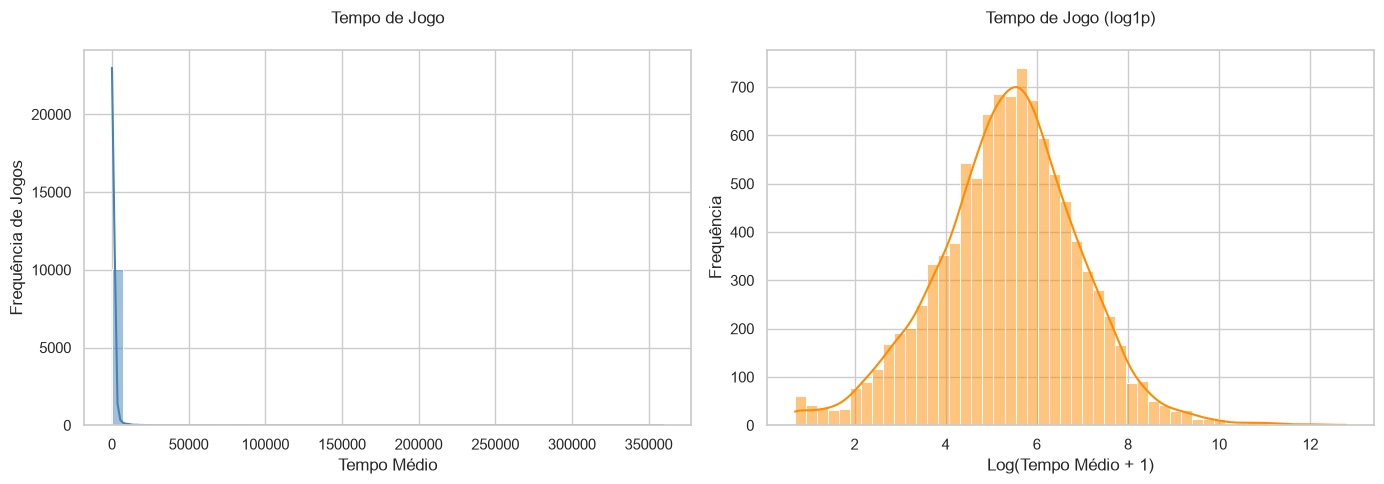

In [21]:
sns.set_theme(style='whitegrid')

# para ver a assimetria observada acima
plt.figure(figsize=(14, 5))

# sbpt 1 - escala normal
plt.subplot(1, 2, 1)
sns.histplot(
    jogos_valid['average_playtime_forever'],
    bins=50,
    color='steelblue',
    kde=True,
)
plt.title('Tempo de Jogo\n')
plt.xlabel('Tempo Médio')
plt.ylabel('Frequência de Jogos')

# sbpt 2: escala logaritmica
plt.subplot(1, 2, 2)
sns.histplot(
    np.log1p(jogos_valid['average_playtime_forever']),
    bins=50,
    color='darkorange',
    kde=True,
)
plt.title(
    'Tempo de Jogo (log1p)\n'
)
plt.xlabel('Log(Tempo Médio + 1)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()



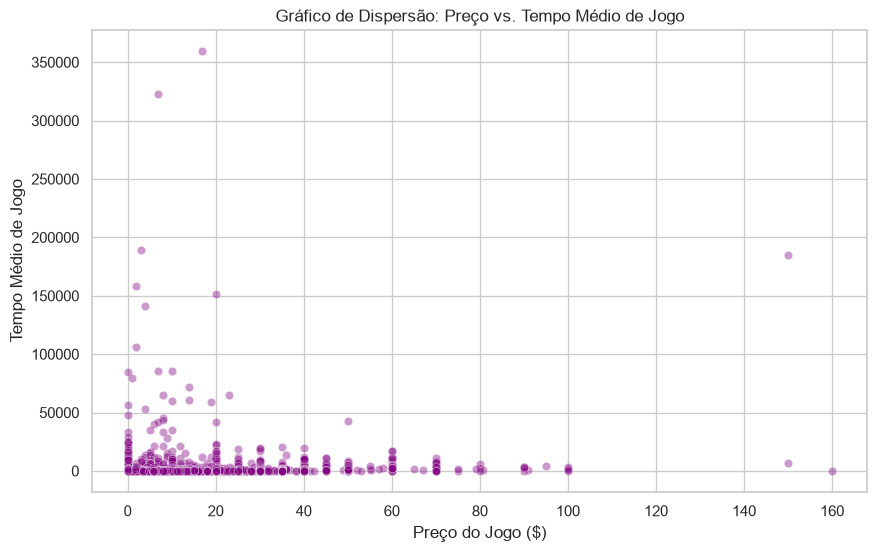

In [20]:
# --- grafico 2: Relação entre Preço e Tempo de Jogo ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=jogos_valid,
    x='price',
    y='average_playtime_forever',
    alpha=0.4,
    color='purple',
)
plt.title(
    'Gráfico de Dispersão: Preço vs. Tempo Médio de Jogo'
)
plt.xlabel('Preço do Jogo ($)')
plt.ylabel('Tempo Médio de Jogo')
plt.show()

### 2.3 Estratificação

RESUMO POR FAIXA DE PREÇO
               faixa_preco  contagem  mediana    q25      q75
0            Gratuito ($0)       519    162.0   48.0   798.00
1    Baixo ($0.01 - $9.99)      4058    139.5   55.0   323.75
2  Médio ($10.00 - $29.99)      4760    277.5  113.0   605.25
3           Alto ($30.00+)       860    937.0  400.0  1890.25


C:\Users\Pedro Gabriel\AppData\Local\Temp\ipykernel_24244\3059986710.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


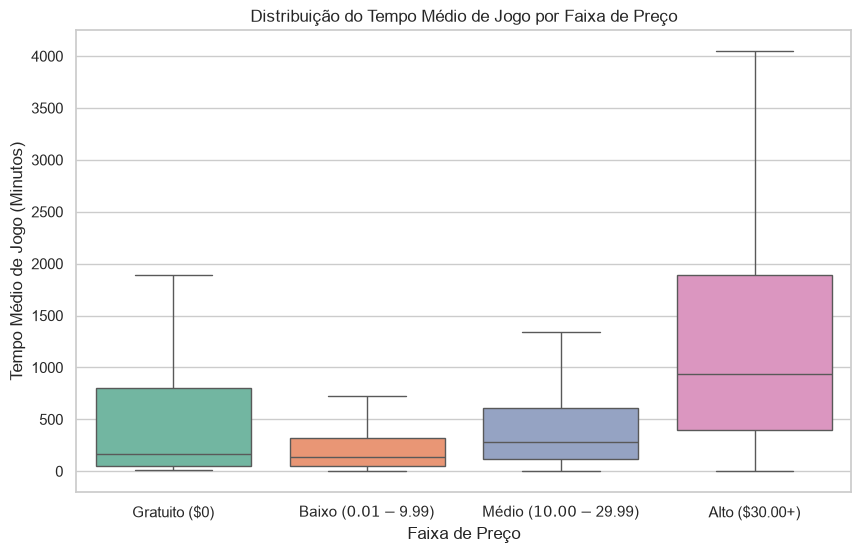

In [27]:
bins = [-0.01, 0.00, 9.99, 29.99, 200.0]
labels = [
    'Gratuito ($0)',
    'Baixo ($0.01 - $9.99)',
    'Médio ($10.00 - $29.99)',
    'Alto ($30.00+)',
]
jogos_valid['faixa_preco'] = pd.cut(
    jogos_valid['price'], bins=bins, labels=labels
)

resumo_faixas = (
    jogos_valid.groupby('faixa_preco', observed=False)['average_playtime_forever']
    .agg(
        contagem='count',
        mediana=lambda x: x.median(),
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)
print('RESUMO POR FAIXA DE PREÇO')
print(resumo_faixas)

# boxplot das faixas
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=jogos_valid,
    x='faixa_preco',
    y='average_playtime_forever',
    showfliers=False,
    palette='Set2',
)
plt.title(
    'Distribuição do Tempo Médio de Jogo por Faixa de Preço'
)
plt.xlabel('Faixa de Preço')
plt.ylabel('Tempo Médio de Jogo (Minutos)')
plt.show()

### 2.4 Análise de segmentação por gênero




In [35]:
import ast

def parse_genres(val):
  if isinstance(val, list):
    return val
  if isinstance(val, str):
    try:
      return ast.literal_eval(val)
    except:
      return []
  return []


# explodindo a coluna
listas_generos = jogos_valid['genres'].apply(parse_genres)
todos_generos = listas_generos.explode().dropna().str.strip()

generos_unicos = todos_generos.unique()

print(f'Total de gêneros únicos encontrados: {len(generos_unicos)}')
print('\nTODOS OS GENEROS')
print(todos_generos.value_counts())

Total de gêneros únicos encontrados: 23

TODOS OS GENEROS
genres
Indie                    6530
Adventure                4594
Action                   3914
Casual                   3688
Simulation               3199
RPG                      2875
Strategy                 2339
Early Access              945
Sports                    443
Free To Play              363
Racing                    303
Massively Multiplayer     220
Utilities                  68
Design & Illustration      40
Animation & Modeling       37
Game Development           23
Video Production           22
Education                  18
Audio Production           17
Photo Editing              15
Software Training          14
Web Publishing              7
Accounting                  1
Name: count, dtype: int64


Visualizando os generos mais comuns (mais de 300)




Gêneros com mais de 300 jogos: ['Indie', 'Adventure', 'Action', 'Casual', 'Simulation', 'RPG', 'Strategy', 'Early Access', 'Sports', 'Free To Play', 'Racing']


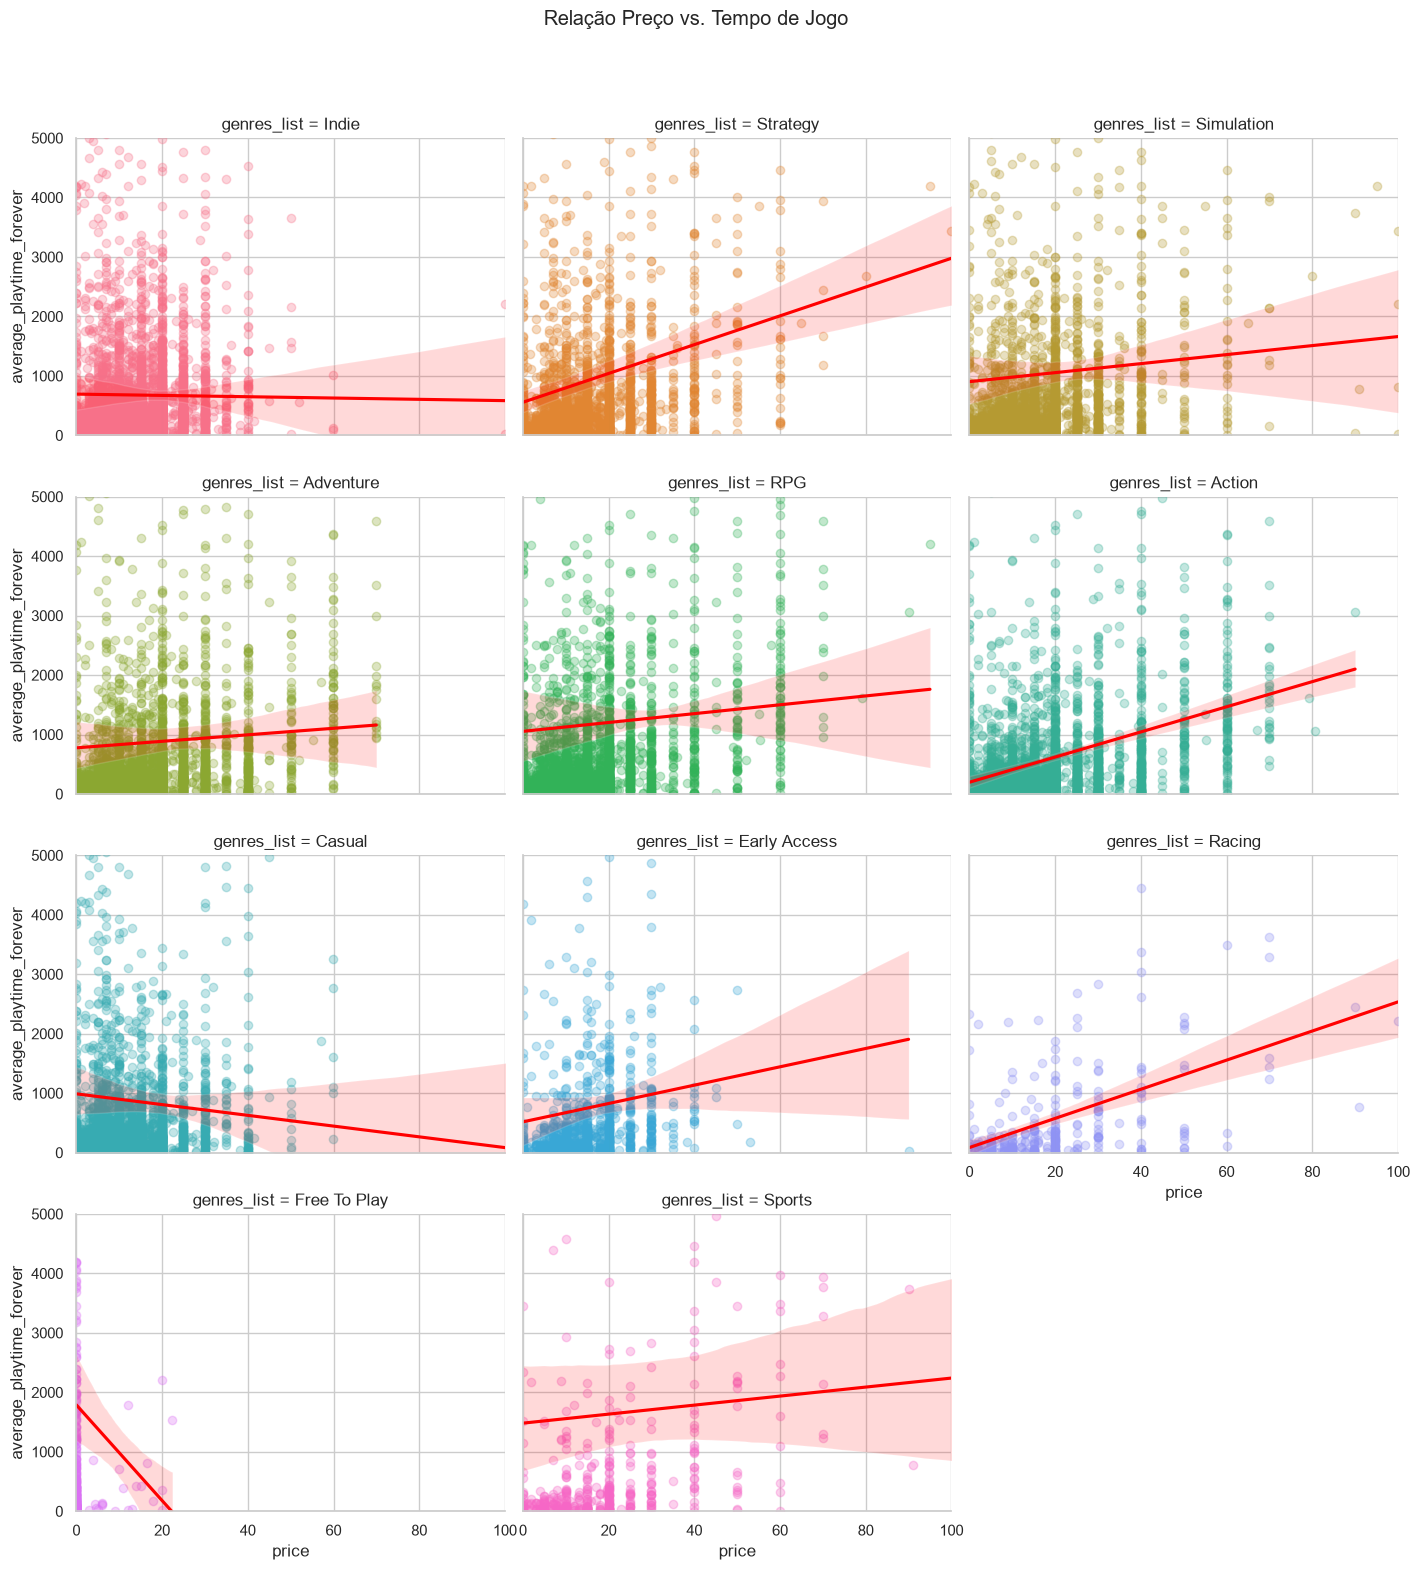

In [38]:
df_generos_explodido = jogos_valid.copy()
df_generos_explodido['genres_list'] = df_generos_explodido['genres'].apply(
    parse_genres
)
df_generos_explodido = df_generos_explodido.explode('genres_list')

# quais generos possuem mais de 300 jogos
contagem_generos = df_generos_explodido['genres_list'].value_counts()
generos_acima_300 = contagem_generos[contagem_generos > 300].index.tolist()

print(f'Gêneros com mais de 300 jogos: {generos_acima_300}')

# filtrando
df_filtrado = df_generos_explodido[
    df_generos_explodido['genres_list'].isin(generos_acima_300)
].copy()

# grafico de dispersão
g = sns.lmplot(
    data=df_filtrado,
    x='price',
    y='average_playtime_forever',
    hue='genres_list',
    col='genres_list',
    col_wrap=3,
    height=4,
    aspect=1.2,
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'},
)

g.set(ylim=(0, 5000), xlim=(0, 100))
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle(
    'Relação Preço vs. Tempo de Jogo'
)
plt.show()

## 3. Teste de Hipótese e Inferência Estatística

- **H₀ (Hipótese Nula):** Não há correlação estatisticamente significativa entre o preço de um jogo e o seu tempo médio jogado.
- **H₁ (Hipótese Alternativa):** Existe uma correlação estatisticamente significativa entre o preço de um jogo e o seu tempo médio jogado
- **Teste estatístico escolhido:** Correlação de Spearman (por ser um teste não paramétrico adequado para analisar a relação entre duas variáveis assimétrics)
- **Nível de significância (α):** 0,05

In [30]:
from scipy import stats

stat, p_valor = stats.spearmanr(
    jogos_valid['price'], jogos_valid['average_playtime_forever']
)

print(f'Coeficiente de Spearman: {stat:.4f}')
print(f'P-valor: {p_valor:.4e}')


Coeficiente de Spearman: 0.3335
P-valor: 2.1586e-263


### 3.1 Teste de hipótese segmentado


A segmentação por gênero foi aplicada para verificar se a correlação positiva observada entre preço e tempo de jogo se mantém constante ou se é moderada pelas características intrínsecas de cada categoria de jogo, como diferentes nichos possuem dinâmicas de engajamento distintas.


In [41]:
df_generos_explodido = jogos_valid.copy()
df_generos_explodido['genres_list'] = df_generos_explodido['genres'].apply(
    parse_genres
)
df_generos_explodido = df_generos_explodido.explode('genres_list')

# filtro
contagem_generos = df_generos_explodido['genres_list'].value_counts()
generos_acima_300 = contagem_generos[contagem_generos > 300].index.tolist()

# correlações
resultados_generos = []

for genero in generos_acima_300:
  sub_df = df_generos_explodido[
      df_generos_explodido['genres_list'] == genero
  ].dropna(subset=['price', 'average_playtime_forever'])

  corr, p_val = stats.spearmanr(sub_df['price'], sub_df['average_playtime_forever'])

  alpha = 0.05
  resultados_generos.append({
      'Gênero': genero,
      'qtd': len(sub_df),
      'Spearman': round(corr, 4),
      'P-valor': p_val,
      'significancia': p_val < alpha,
  })

# exibição
df_resumo_generos = pd.DataFrame(resultados_generos)
print('CORRELAÇÃO DE SPERMAN POR GENERO')
print(
    df_resumo_generos.sort_values(by='Spearman', ascending=False).to_string(
        index=False
    )
)

CORRELAÇÃO DE SPERMAN POR GENERO
      Gênero  qtd  Spearman       P-valor  significancia
      Racing  303    0.4511  1.364593e-16           True
   Adventure 4594    0.3806 2.789542e-158           True
      Action 3914    0.3745 1.520239e-130           True
         RPG 2875    0.3326  3.320285e-75           True
      Sports  443    0.3247  2.448928e-12           True
  Simulation 3199    0.3238  5.455573e-79           True
Early Access  945    0.2959  1.509566e-20           True
    Strategy 2339    0.2946  4.871392e-48           True
       Indie 6530    0.2821 1.031066e-119           True
      Casual 3688    0.2278  1.267132e-44           True
Free To Play  363   -0.0354  5.017171e-01          False


## 4. Conclusão

- **Interpretação dos resultados:** O teste de Spearman aplicado entre o preço e o tempo médio de jogo resultou em um coeficiente de 0,3335 com um p-valor extremamente reduzido. O coeficiente indica uma correlação positiva moderada e monotônica: à medida que o preço do jogo aumenta, o tempo médio despendido pelos jogadores também tende a subir. O p-valor muito baixo valida a significancia estatística do teste.
- **Conclusão:** Rejeita-se a hipótese nula. Resposta à pergunta de pesquisa: Sim, a amostra avaliada indica a existência de uma relação estatística significativa entre o preço de um jogo e o tempo médio jogado. Jogos de maior valor comercial apresentam, em média, maior retenção de tempo por parte dos usuários em comparação aos jogos de menor custo.
- **Análise Complementar:** A desagregação por categorias demonstrou que a correlação positiva entre preço e engajamento se manifesta de forma consistente na maioria dos gêneros principais da plataforma. Apenas o segmento Free To Play não apresentou correlação estatisticamente significativa, evidenciando, talvez, que em jogos gratuitos o modelo de monetização por preço deixa de ser um fator preditivo para o tempo de retenção do usuário.
